<a href="https://colab.research.google.com/github/ahmadfaiz93963-ui/loan-approval-prediction-/blob/main/Loan_Approval_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving loan_approval_dataset.zip to loan_approval_dataset (1).zip


In [ ]:
import zipfile
import os

zip_name = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_name, "r") as zip_file:
    zip_file.extractall("loan_dataset")

os.listdir("loan_dataset")

['train_u6lujuX_CVtuZ9i (1).csv']

In [ ]:
import os
import pandas as pd

file_name = os.listdir("loan_dataset")[0]
loan_data = pd.read_csv("loan_dataset/" + file_name)

print(loan_data.shape)
loan_data.head()

(614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [ ]:
loan_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [ ]:
loan_data["Loan_Status"].value_counts()

,count
Loan_Status,
Y,422
N,192


In [ ]:
loan_data.isnull().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


In [ ]:
loan_data.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


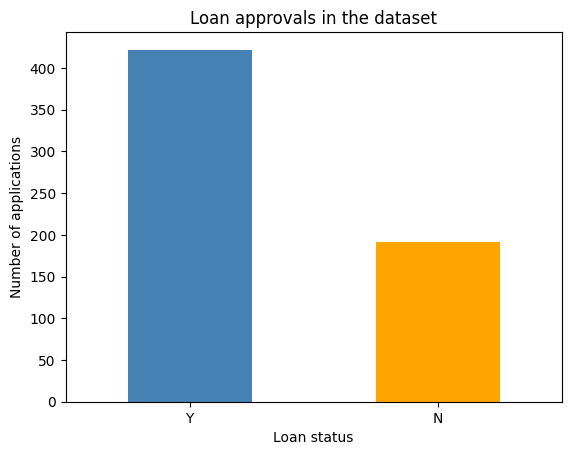

In [ ]:
import matplotlib.pyplot as plt

loan_data["Loan_Status"].value_counts().plot(kind="bar", color=["steelblue", "orange"])
plt.xlabel("Loan status")
plt.ylabel("Number of applications")
plt.title("Loan approvals in the dataset")
plt.xticks(rotation=0)
plt.show()

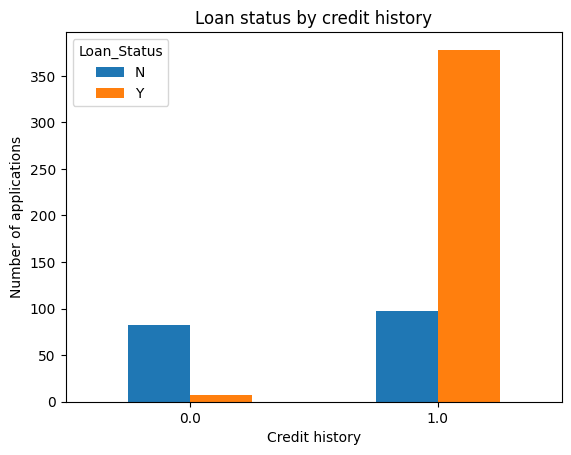

In [ ]:
pd.crosstab(loan_data["Credit_History"], loan_data["Loan_Status"]).plot(kind="bar")
plt.xlabel("Credit history")
plt.ylabel("Number of applications")
plt.title("Loan status by credit history")
plt.xticks(rotation=0)
plt.show()

In [ ]:
loan_data["Gender"] = loan_data["Gender"].fillna(loan_data["Gender"].mode()[0])
loan_data["Married"] = loan_data["Married"].fillna(loan_data["Married"].mode()[0])
loan_data["Dependents"] = loan_data["Dependents"].fillna(loan_data["Dependents"].mode()[0])
loan_data["Self_Employed"] = loan_data["Self_Employed"].fillna(loan_data["Self_Employed"].mode()[0])

In [ ]:
loan_data["LoanAmount"] = loan_data["LoanAmount"].fillna(loan_data["LoanAmount"].median())
loan_data["Loan_Amount_Term"] = loan_data["Loan_Amount_Term"].fillna(loan_data["Loan_Amount_Term"].mode()[0])
loan_data["Credit_History"] = loan_data["Credit_History"].fillna(loan_data["Credit_History"].mode()[0])

In [ ]:
loan_data.isnull().sum().sum()

np.int64(0)

In [ ]:
X = loan_data.drop(columns=["Loan_ID", "Loan_Status"])
y = loan_data["Loan_Status"]

print("Applicant details:", X.shape)
print("Loan decisions:", y.shape)

Applicant details: (614, 11)
Loan decisions: (614,)


In [ ]:
X = pd.get_dummies(X, dtype=int)
y = y.map({"N": 0, "Y": 1})

print("Model input columns:", X.shape[1])
X.head()

Model input columns: 20


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender_Female,Gender_Male,Married_No,Married_Yes,Dependents_0,Dependents_1,Dependents_2,Dependents_3+,Education_Graduate,Education_Not Graduate,Self_Employed_No,Self_Employed_Yes,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban
0,5849,0.0,128.0,360.0,1.0,0,1,1,0,1,0,0,0,1,0,1,0,0,0,1
1,4583,1508.0,128.0,360.0,1.0,0,1,0,1,0,1,0,0,1,0,1,0,1,0,0
2,3000,0.0,66.0,360.0,1.0,0,1,0,1,1,0,0,0,1,0,0,1,0,0,1
3,2583,2358.0,120.0,360.0,1.0,0,1,0,1,1,0,0,0,0,1,1,0,0,0,1
4,6000,0.0,141.0,360.0,1.0,0,1,1,0,1,0,0,0,1,0,1,0,0,0,1


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training applications:", len(X_train))
print("Test applications:", len(X_test))

Training applications: 491
Test applications: 123


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [ ]:
from sklearn.linear_model import LogisticRegression

loan_model = LogisticRegression(max_iter=1000)
loan_model.fit(X_train_scaled, y_train)

print("Model training complete")

Model training complete


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

loan_predictions = loan_model.predict(X_test_scaled)

print(confusion_matrix(y_test, loan_predictions))
print(classification_report(
    y_test,
    loan_predictions,
    target_names=["Not approved", "Approved"]
))

[[22 16]
 [ 1 84]]
              precision    recall  f1-score   support

Not approved       0.96      0.58      0.72        38
    Approved       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



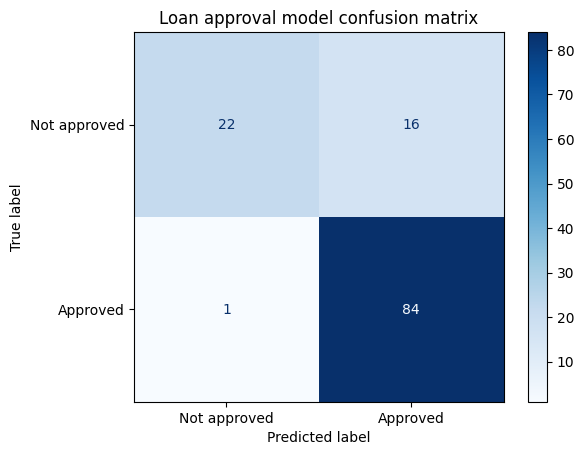

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    loan_predictions,
    display_labels=["Not approved", "Approved"],
    cmap="Blues",
    values_format="d"
)
plt.title("Loan approval model confusion matrix")
plt.show()

In [ ]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(max_depth=4, random_state=42)
tree_model.fit(X_train, y_train)

print("Decision Tree training complete")

Decision Tree training complete


In [ ]:
tree_predictions = tree_model.predict(X_test)

print(confusion_matrix(y_test, tree_predictions))
print(classification_report(
    y_test,
    tree_predictions,
    target_names=["Not approved", "Approved"]
))

[[20 18]
 [ 1 84]]
              precision    recall  f1-score   support

Not approved       0.95      0.53      0.68        38
    Approved       0.82      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.76      0.79       123
weighted avg       0.86      0.85      0.83       123



In [ ]:
from sklearn.ensemble import RandomForestClassifier

forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
forest_model.fit(X_train, y_train)

print("Random Forest training complete")

Random Forest training complete


In [ ]:
forest_predictions = forest_model.predict(X_test)

print(confusion_matrix(y_test, forest_predictions))
print(classification_report(
    y_test,
    forest_predictions,
    target_names=["Not approved", "Approved"]
))

[[24 14]
 [ 8 77]]
              precision    recall  f1-score   support

Not approved       0.75      0.63      0.69        38
    Approved       0.85      0.91      0.88        85

    accuracy                           0.82       123
   macro avg       0.80      0.77      0.78       123
weighted avg       0.82      0.82      0.82       123



In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, loan_predictions),
        accuracy_score(y_test, tree_predictions),
        accuracy_score(y_test, forest_predictions)
    ],
    "Approved precision": [
        precision_score(y_test, loan_predictions, zero_division=0),
        precision_score(y_test, tree_predictions, zero_division=0),
        precision_score(y_test, forest_predictions, zero_division=0)
    ],
    "Approved recall": [
        recall_score(y_test, loan_predictions, zero_division=0),
        recall_score(y_test, tree_predictions, zero_division=0),
        recall_score(y_test, forest_predictions, zero_division=0)
    ],
    "Approved F1-score": [
        f1_score(y_test, loan_predictions, zero_division=0),
        f1_score(y_test, tree_predictions, zero_division=0),
        f1_score(y_test, forest_predictions, zero_division=0)
    ]
})

model_comparison

,Model,Accuracy,Approved precision,Approved recall,Approved F1-score
0,Logistic Regression,0.861789,0.840000,0.988235,0.908108
1,Decision Tree,0.845528,0.823529,0.988235,0.898396
2,Random Forest,0.821138,0.846154,0.905882,0.875000


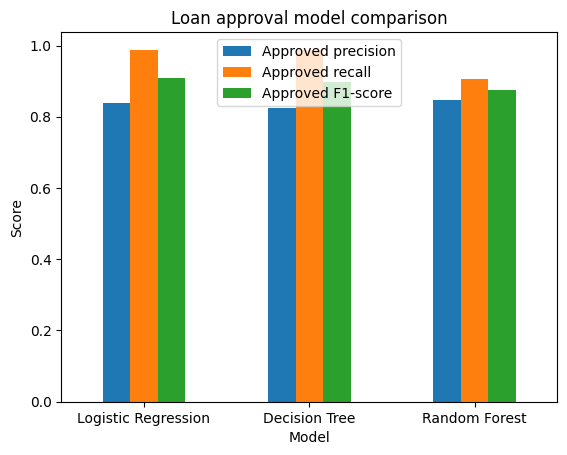

In [ ]:
model_comparison.set_index("Model")[
    ["Approved precision", "Approved recall", "Approved F1-score"]
].plot(kind="bar")

plt.ylabel("Score")
plt.title("Loan approval model comparison")
plt.xticks(rotation=0)
plt.show()

In [ ]:
import joblib

joblib.dump(loan_model, "logistic_regression_model.pkl")
joblib.dump(tree_model, "decision_tree_model.pkl")
joblib.dump(forest_model, "random_forest_model.pkl")
joblib.dump(scaler, "loan_data_scaler.pkl")
joblib.dump(list(X.columns), "loan_feature_columns.pkl")

print("Models and supporting files saved")

Models and supporting files saved


In [ ]:
from google.colab import files

files.download("logistic_regression_model.pkl")
files.download("decision_tree_model.pkl")
files.download("random_forest_model.pkl")
files.download("loan_data_scaler.pkl")
files.download("loan_feature_columns.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
sample_application = X_test.iloc[[0]]
sample_application_scaled = scaler.transform(sample_application)

model_predictions = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Prediction": [
        loan_model.predict(sample_application_scaled)[0],
        tree_model.predict(sample_application)[0],
        forest_model.predict(sample_application)[0]
    ]
})

model_predictions["Prediction"] = model_predictions["Prediction"].map({
    0: "Not approved",
    1: "Approved"
})

actual_decision = "Approved" if y_test.iloc[0] == 1 else "Not approved"

print("Actual decision:", actual_decision)
model_predictions

Actual decision: Not approved


,Model,Prediction
0,Logistic Regression,Not approved
1,Decision Tree,Not approved
2,Random Forest,Not approved
